In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# data loading
file_path = "OTT_Viewer_DropOff_Retention_Risk.csv"

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")


Dataset Loaded Successfully!


In [4]:
df.head()

,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,...,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk
0,SHOW_0130,Synthetic_Show_0130,ViewNow,Comedy,2018,2,17,35,4.99,6.28,...,82.51,1,1,Yes,5.45,Medium,Yes,0,0.0400,Low
1,SHOW_0902,Synthetic_Show_0902,Hotstar,Action,2024,2,9,42,7.49,5.01,...,65.56,5,2,No,5.34,Medium,No,1,0.0648,Low
2,SHOW_0517,Synthetic_Show_0517,CinePlay,Crime,2021,1,13,20,8.36,6.26,...,96.79,3,1,Yes,8.53,High,Yes,0,0.0188,Low
3,SHOW_0558,Synthetic_Show_0558,StreamPlus,Comedy,2025,2,16,57,7.46,7.57,...,69.83,2,3,Yes,6.36,Medium,Yes,0,0.0238,Low
4,SHOW_0567,Synthetic_Show_0567,Hotstar,Thriller,2021,2,1,38,6.98,6.57,...,81.59,0,2,Yes,6.35,Medium,No,0,0.0161,Low


In [5]:
df.tail()

,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,...,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk
33195,SHOW_0505,Synthetic_Show_0505,StreamPlus,Comedy,2022,2,3,26,5.32,7.16,...,73.93,1,2,Yes,6.04,Medium,Yes,0,0.0257,Low
33196,SHOW_0185,Synthetic_Show_0185,ViewNow,Romance,2024,1,10,20,5.70,2.09,...,64.03,0,3,Yes,6.43,Medium,Yes,0,0.0801,Low
33197,SHOW_0336,Synthetic_Show_0336,CinePlay,Romance,2020,2,14,26,6.90,5.38,...,90.88,2,0,Yes,6.33,Medium,No,0,0.0066,Low
33198,SHOW_0026,Synthetic_Show_0026,CinePlay,Family,2022,1,11,32,5.68,5.38,...,71.06,2,5,Yes,6.01,Medium,No,0,0.0399,Low
33199,SHOW_0473,Synthetic_Show_0473,ViewNow,Romance,2024,2,4,33,7.52,4.65,...,89.06,2,0,Yes,5.76,Medium,Yes,0,0.0202,Low


In [6]:
df.sample(5, random_state=42)

,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,...,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk
4419,SHOW_0322,Synthetic_Show_0322,StreamPlus,Action,2018,2,13,55,5.66,4.38,...,72.21,2,3,No,7.34,High,No,0,0.0811,Low
29957,SHOW_0351,Synthetic_Show_0351,Hotstar,Reality,2025,1,5,37,9.00,6.26,...,69.49,4,2,Yes,5.46,Medium,Yes,0,0.0457,Low
17240,SHOW_0119,Synthetic_Show_0119,ViewNow,Sci-Fi,2026,2,11,62,5.70,5.69,...,83.72,1,4,No,4.57,Medium,Yes,0,0.0081,Low
18612,SHOW_0400,Synthetic_Show_0400,StreamPlus,Drama,2020,2,2,38,7.33,5.13,...,74.77,1,2,No,6.92,Medium,No,0,0.0198,Low
18894,SHOW_0075,Synthetic_Show_0075,Hotstar,Reality,2018,1,2,44,5.54,6.04,...,58.42,0,1,No,3.90,Low,No,0,0.0831,Low


In [7]:
# data understanding
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Total Rows: 33200
Total Columns: 22


In [8]:
print(df.columns.tolist())

['show_id', 'title', 'platform', 'genre', 'release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro', 'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off', 'drop_off_probability', 'retention_risk']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33200 entries, 0 to 33199
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   show_id               33200 non-null  str    
 1   title                 33200 non-null  str    
 2   platform              33200 non-null  str    
 3   genre                 33200 non-null  str    
 4   release_year          33200 non-null  int64  
 5   season_number         33200 non-null  int64  
 6   episode_number        33200 non-null  int64  
 7   episode_duration_min  33200 non-null  int64  
 8   pacing_score          33200 non-null  float64
 9   hook_strength         33200 non-null  float64
 10  dialogue_density      33200 non-null  float64
 11  visual_intensity      33200 non-null  float64
 12  avg_watch_percentage  33200 non-null  float64
 13  pause_count           33200 non-null  int64  
 14  rewind_count          33200 non-null  int64  
 15  skip_intro            33200 no

In [10]:
df.describe()

,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,dialogue_density,visual_intensity,avg_watch_percentage,pause_count,rewind_count,cognitive_load,drop_off,drop_off_probability
count,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000,33200.000000
mean,2021.998373,1.512048,8.807229,41.797349,6.190692,5.995332,5.496035,5.991559,81.464080,1.665542,1.514518,6.171689,0.045271,0.043858
std,2.585237,0.499862,4.795798,12.532480,1.669892,1.847390,1.949428,1.779830,11.971238,1.346504,1.251897,1.325081,0.207901,0.055309
min,2018.000000,1.000000,1.000000,20.000000,1.000000,1.000000,1.000000,1.000000,30.470000,0.000000,0.000000,1.000000,0.000000,0.000500
25%,2020.000000,1.000000,5.000000,33.000000,5.050000,4.750000,4.150000,4.790000,73.240000,1.000000,1.000000,5.280000,0.000000,0.011800
50%,2022.000000,2.000000,9.000000,42.000000,6.190000,6.000000,5.500000,6.000000,81.870000,1.000000,1.000000,6.180000,0.000000,0.024900
75%,2024.000000,2.000000,13.000000,50.000000,7.340000,7.270000,6.850000,7.210000,90.690000,2.000000,2.000000,7.060000,0.000000,0.053200
max,2026.000000,2.000000,17.000000,90.000000,10.000000,10.000000,10.000000,10.000000,100.000000,10.000000,9.000000,10.000000,1.000000,0.766200


In [11]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

print(numeric_columns.tolist())

['release_year', 'season_number', 'episode_number', 'episode_duration_min', 'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity', 'avg_watch_percentage', 'pause_count', 'rewind_count', 'cognitive_load', 'drop_off', 'drop_off_probability']


In [12]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

print(categorical_columns.tolist())

['show_id', 'title', 'platform', 'genre', 'skip_intro', 'attention_required', 'night_watch_safe', 'retention_risk']


In [13]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])


Series([], dtype: int64)


In [14]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage.sort_values(ascending=False))

show_id                 0.0
title                   0.0
platform                0.0
genre                   0.0
release_year            0.0
season_number           0.0
episode_number          0.0
episode_duration_min    0.0
pacing_score            0.0
hook_strength           0.0
dialogue_density        0.0
visual_intensity        0.0
avg_watch_percentage    0.0
pause_count             0.0
rewind_count            0.0
skip_intro              0.0
cognitive_load          0.0
attention_required      0.0
night_watch_safe        0.0
drop_off                0.0
drop_off_probability    0.0
retention_risk          0.0
dtype: float64


In [15]:
df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

Shape After Removing Duplicates: (33200, 22)


In [16]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [17]:
# data cleaning

df.colums = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)


In [18]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

In [19]:
print(df.isnull().sum())

show_id                 0
title                   0
platform                0
genre                   0
release_year            0
season_number           0
episode_number          0
episode_duration_min    0
pacing_score            0
hook_strength           0
dialogue_density        0
visual_intensity        0
avg_watch_percentage    0
pause_count             0
rewind_count            0
skip_intro              0
cognitive_load          0
attention_required      0
night_watch_safe        0
drop_off                0
drop_off_probability    0
retention_risk          0
dtype: int64


In [20]:
important_numeric = [
    "episode_duration_min",
    "pacing_score",
    "hook_strength",
    "dialogue_density",
    "visual_intensity",
    "avg_watch_percentage",
    "pause_count",
    "rewind_count",
    "cognitive_load",
    "drop_off_probability"
]

for col in important_numeric:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

In [21]:
if "avg_watch_percentage" in df.columns:
    print(
        df[
            (df["avg_watch_percentage"] < 0 ) |
            (df["avg_watch_percentage"] > 100)
        ]
    )

if "drop_off_probability" in df.columns:
    print(
        df[
            (df["drop_off_probability"] < 0) |
            (df["drop_off_probability"] > 1)
        ]
    )

Empty DataFrame
Columns: [show_id, title, platform, genre, release_year, season_number, episode_number, episode_duration_min, pacing_score, hook_strength, dialogue_density, visual_intensity, avg_watch_percentage, pause_count, rewind_count, skip_intro, cognitive_load, attention_required, night_watch_safe, drop_off, drop_off_probability, retention_risk]
Index: []

[0 rows x 22 columns]
Empty DataFrame
Columns: [show_id, title, platform, genre, release_year, season_number, episode_number, episode_duration_min, pacing_score, hook_strength, dialogue_density, visual_intensity, avg_watch_percentage, pause_count, rewind_count, skip_intro, cognitive_load, attention_required, night_watch_safe, drop_off, drop_off_probability, retention_risk]
Index: []

[0 rows x 22 columns]


In [22]:
for col in important_numeric:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

In [23]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("unknown")
    

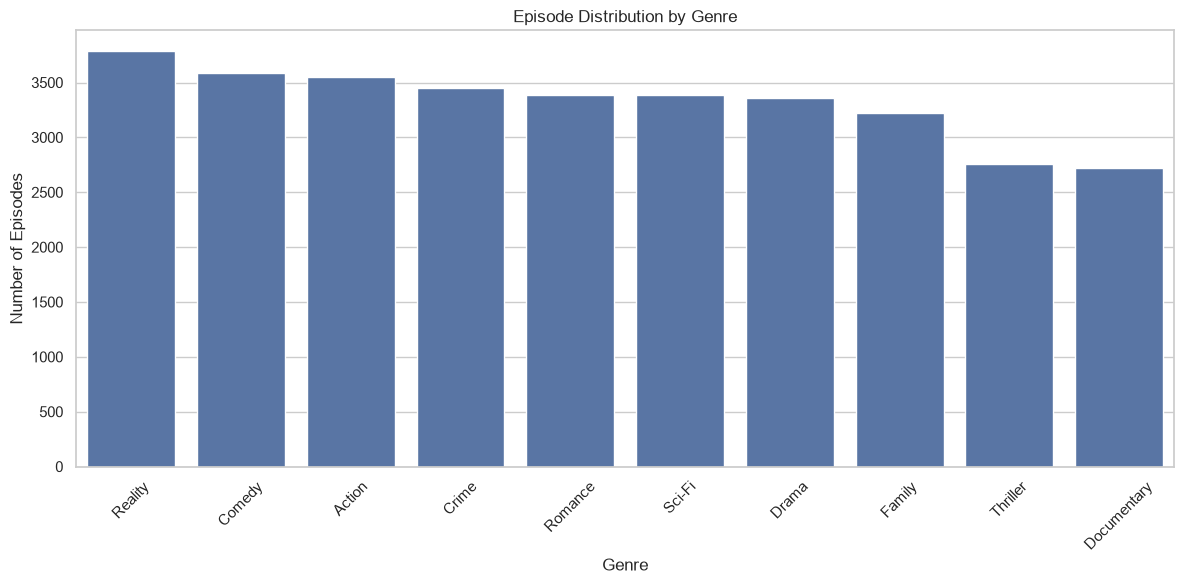

In [24]:
# genre analysis
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="genre",
    order=df["genre"].value_counts().index
)

plt.title("Episode Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Episodes")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

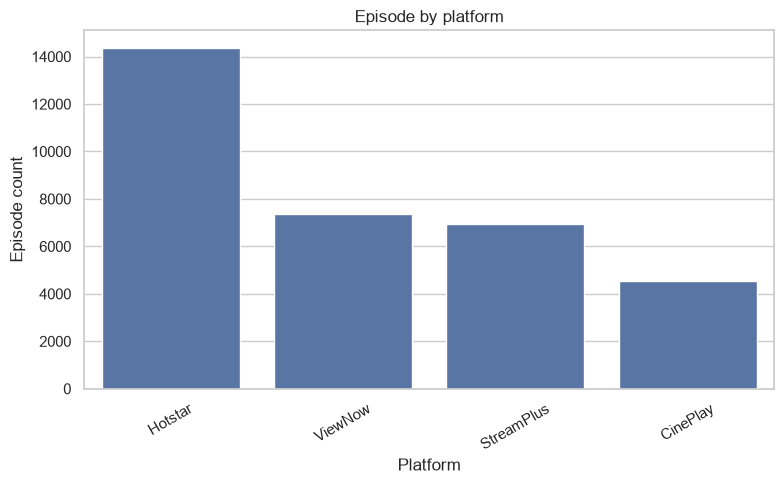

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="platform",
    order=df["platform"].value_counts().index
)

plt.title("Episode by platform")
plt.xlabel("Platform")
plt.ylabel("Episode count")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

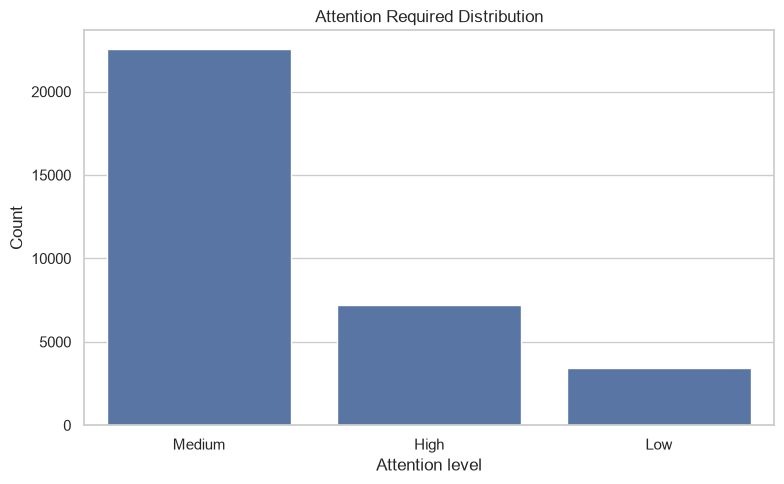

In [26]:
# attention required
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="attention_required"
)

plt.title("Attention Required Distribution")
plt.xlabel("Attention level")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

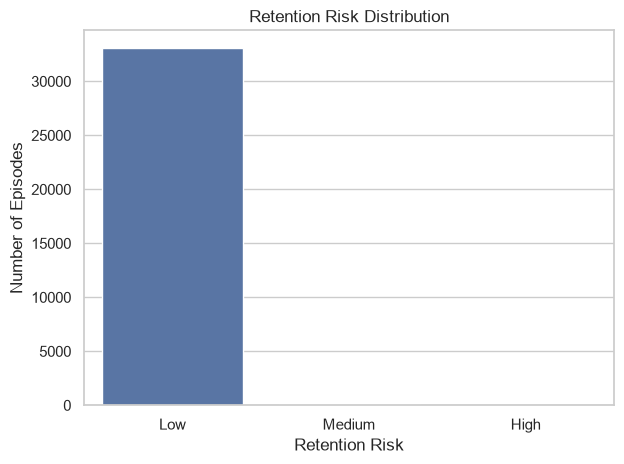

In [27]:
# retention Risk 
plt.Figure(figsize=(8, 5))

sns.countplot(
    data=df, 
    x="retention_risk",
    order=df["retention_risk"].value_counts().index
)

plt.title("Retention Risk Distribution")
plt.xlabel("Retention Risk")
plt.ylabel("Number of Episodes")

plt.tight_layout()
plt.show()

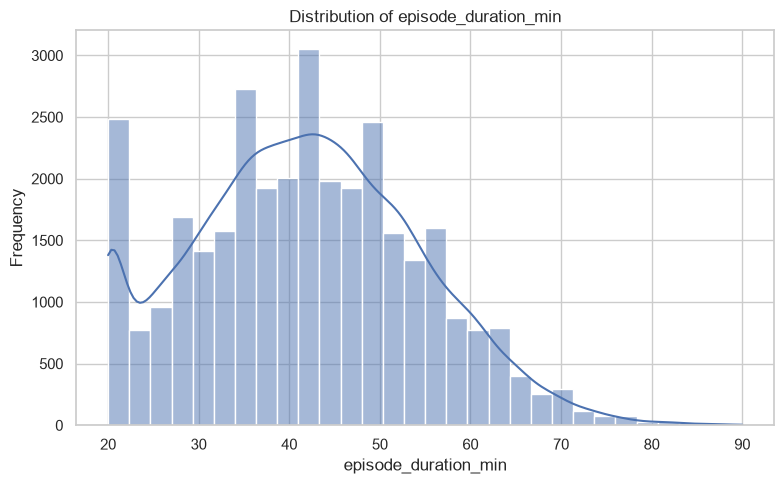

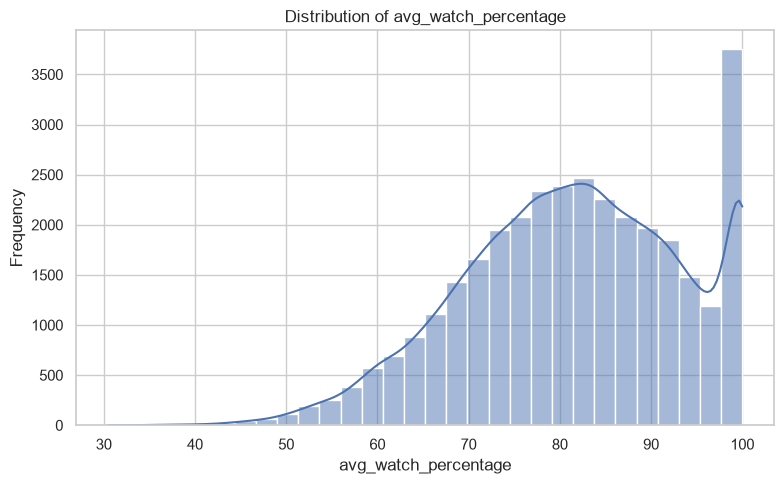

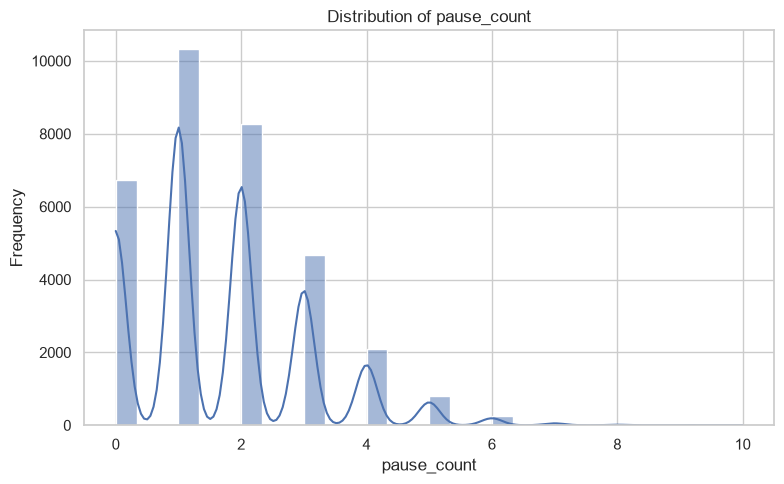

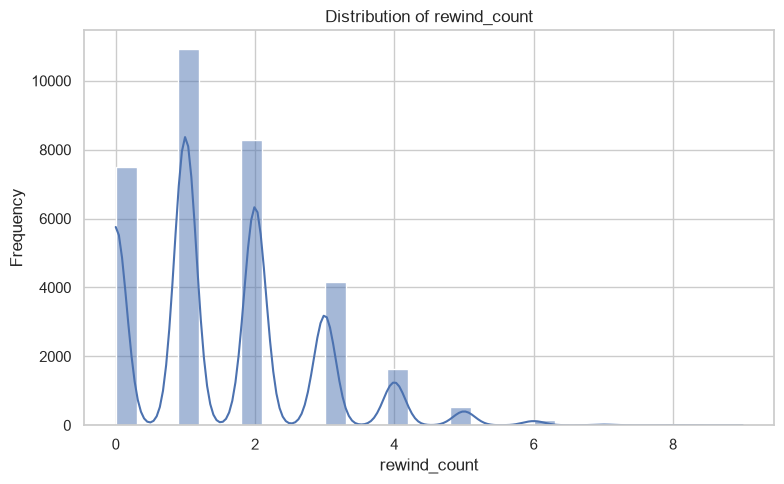

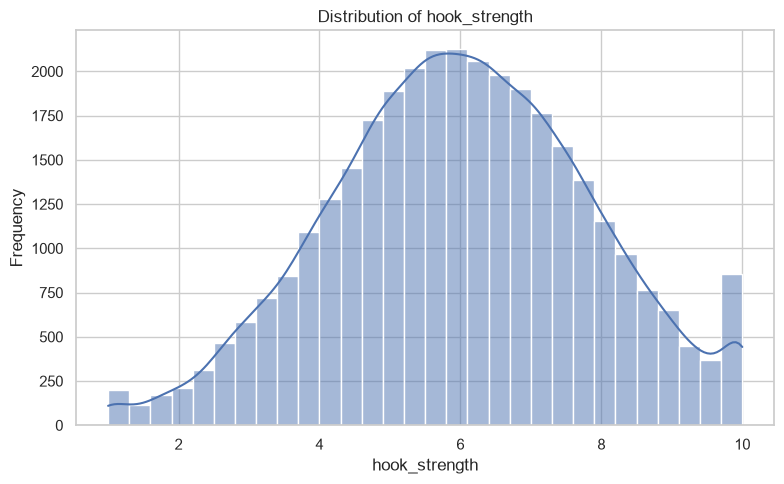

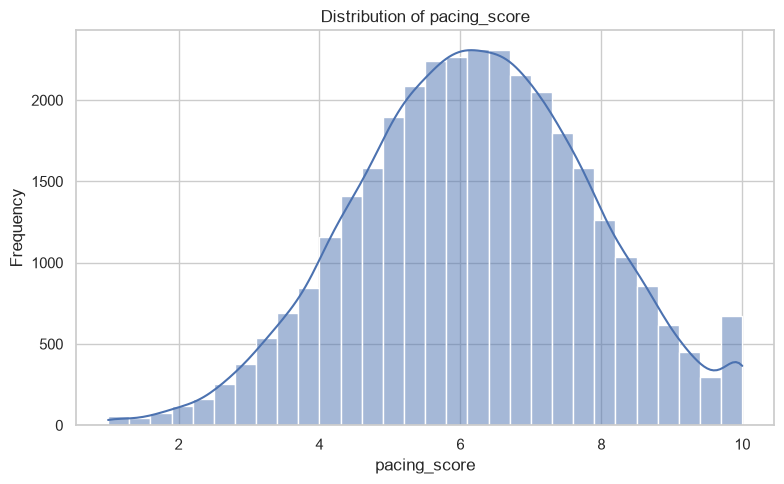

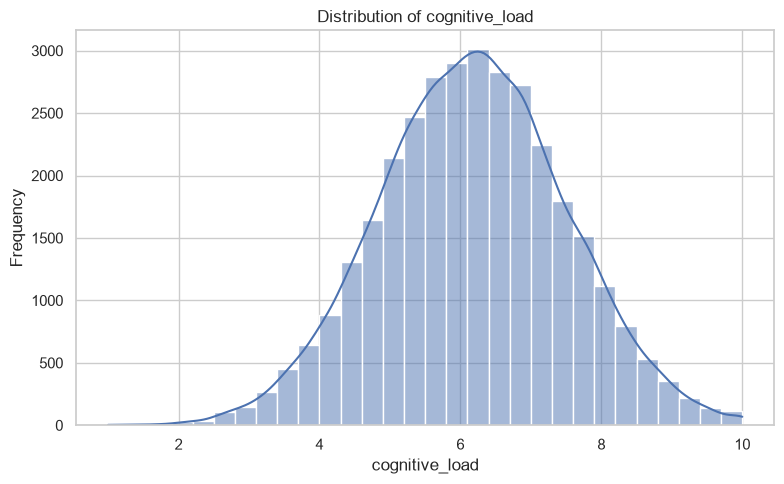

In [28]:
# numerical distribution analysis
numerical_features = [
    "episode_duration_min",
    "avg_watch_percentage",
    "pause_count",
    "rewind_count",
    "hook_strength",
    "pacing_score",
    "cognitive_load",
    "drop_off_probabity",
]

for col in numerical_features:
    if col in df.columns:

        plt.figure(figsize=(8, 5))

        sns.histplot(
            data=df,
            x=col,
            bins=30,
            kde=True
        )

        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")

        plt.tight_layout()
        plt.show()

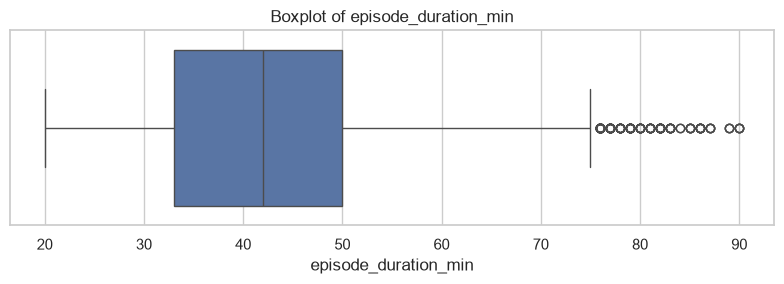

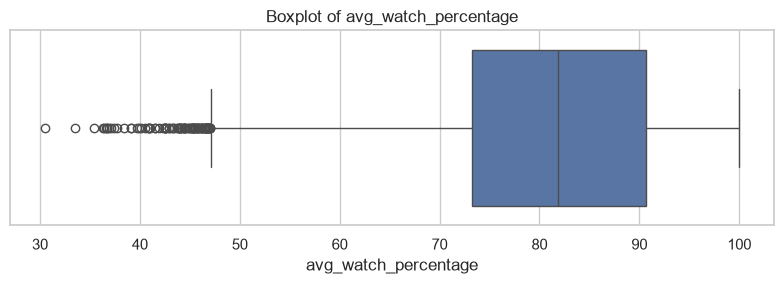

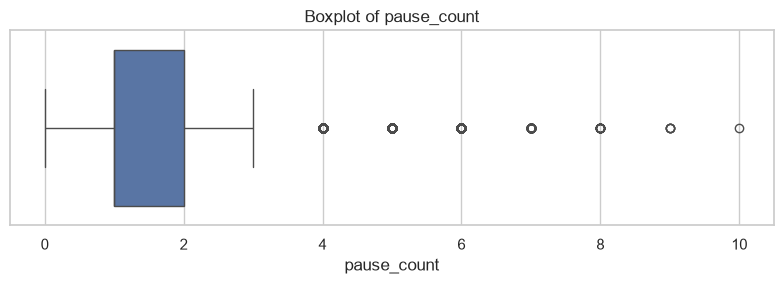

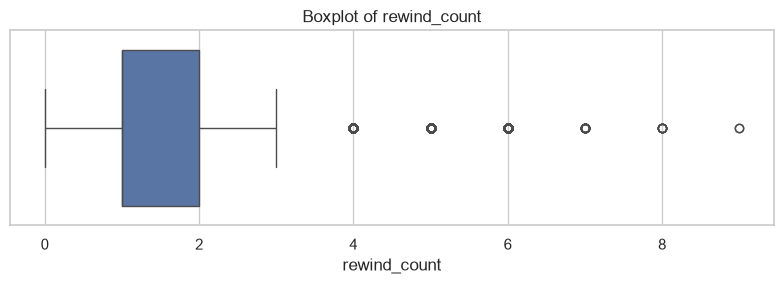

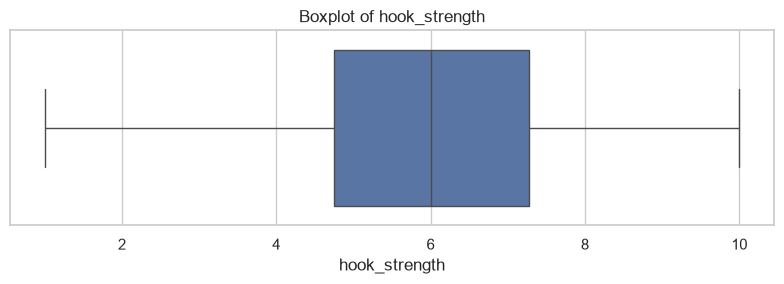

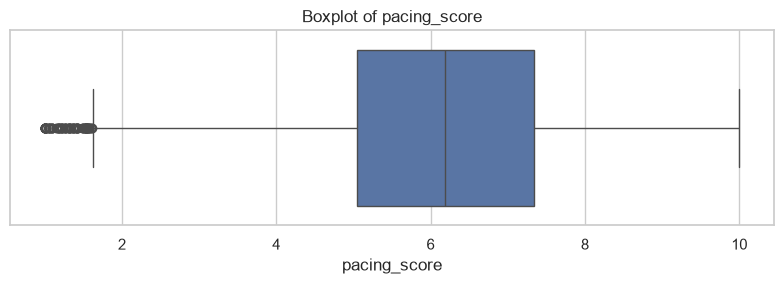

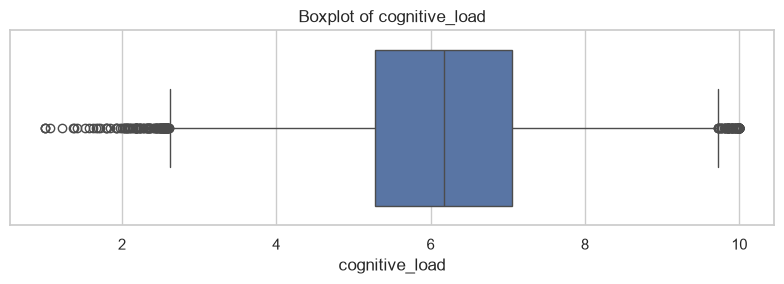

In [29]:
for col in numerical_features:

    if col in df.columns:

        plt.figure(figsize=(8,3))

        sns.boxplot(
            data=df,
            x=col,
        )

        plt.title(f"Boxplot of {col}")

        plt.tight_layout()
        plt.show()

In [30]:
# viwer engagement analysis
df["engagement_score"] = (
    df["avg_watch_percentage"]
    + df["hook_strength"] * 5
    + df["pacing_score"] * 5
    + df["visual_intensity"] * 5
) / 2

In [31]:
df["engagement_score"] = (
    0.40 * df["avg_watch_percentage"]
    + 0.20 * df["hook_strength"] * 10
    + 0.20 * df["pacing_score"] * 10
    + 0.20 * df["visual_intensity"] * 10
)

In [32]:
# engagement score summary
df["engagement_score"].describe()

count    33200.000000
mean        68.940799
std          9.291843
min         28.076000
25%         62.643000
50%         69.120000
75%         75.553000
max         98.600000
Name: engagement_score, dtype: float64

In [33]:
# top 10 engaged episodes
top_10_engaged = df.sort_values(
    by="engagement_score",
    ascending=False
).head(10)

top_10_engaged[
    [
        "title",
        "genre",
        "season_number",
        "episode_number",
        "engagement_score"
    ]
]

,title,genre,season_number,episode_number,engagement_score
18688,Synthetic_Show_0606,Action,1,10,98.600
27846,Synthetic_Show_0456,Comedy,1,12,97.940
31106,Synthetic_Show_0515,Family,1,1,97.624
32503,Synthetic_Show_0730,Reality,2,13,97.360
27175,Synthetic_Show_0764,Family,1,2,96.980
118,Synthetic_Show_0046,Comedy,1,1,96.340
12602,Synthetic_Show_0728,Family,1,7,95.780
8635,Synthetic_Show_0472,Family,1,2,95.480
19387,Synthetic_Show_0276,Romance,2,2,95.420
6418,Synthetic_Show_0359,Family,1,3,95.200


In [34]:
# lowest 10 engaged episodes
bottom_10_engaged = df.sort_values(
    by="engagement_score",
    ascending=True
).head(10)

bottom_10_engaged[
    [
        "title",
        "genre",
        "season_number",
        "episode_number",
        "engagement_score"
    ]
]

,title,genre,season_number,episode_number,engagement_score
21457,Synthetic_Show_0628,Sci-Fi,2,7,28.076
32722,Synthetic_Show_0258,Crime,1,11,31.164
22513,Synthetic_Show_0972,Action,1,3,34.196
14220,Synthetic_Show_0488,Thriller,2,1,34.336
3315,Synthetic_Show_0983,Family,2,15,35.072
27260,Synthetic_Show_0167,Family,1,17,35.160
14481,Synthetic_Show_0957,Thriller,2,17,35.736
31470,Synthetic_Show_0024,Sci-Fi,2,8,36.572
32399,Synthetic_Show_0563,Reality,2,16,37.052
10254,Synthetic_Show_0896,Crime,1,3,37.576


In [35]:
# genre-wise engagment

genre_engagement = (
    df.groupby("genre")["engagement_score"]
    .mean()
    .sort_values(ascending=False)
)

print(genre_engagement)

genre
Romance        69.160471
Action         69.101400
Reality        69.039784
Drama          68.980537
Crime          68.965081
Family         68.940888
Thriller       68.904365
Comedy         68.871647
Sci-Fi         68.759319
Documentary    68.594118
Name: engagement_score, dtype: float64


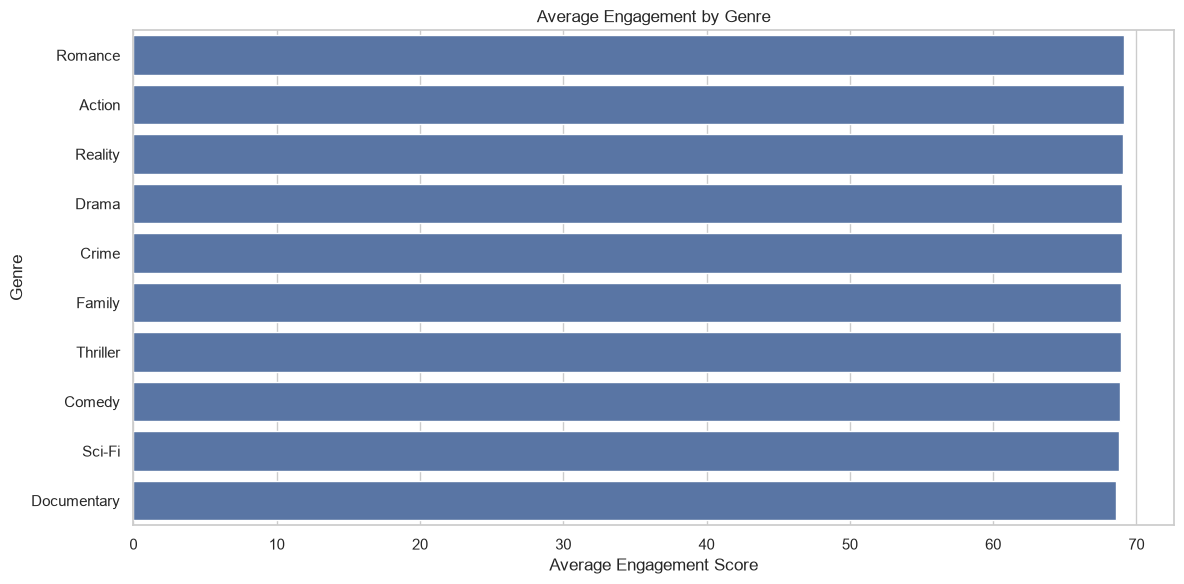

In [36]:
# graph
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_engagement.values,
    y=genre_engagement.index
)

plt.title("Average Engagement by Genre")
plt.xlabel("Average Engagement Score")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [37]:
# watch % anlaysis by genre
genre_watch = (
    df.groupby("genre")["avg_watch_percentage"]
    .mean()
    .sort_values(ascending=False)
)

print(genre_watch)

genre
Romance        81.876901
Action         81.684379
Reality        81.658972
Family         81.610469
Crime          81.463572
Thriller       81.439322
Drama          81.426632
Comedy         81.353477
Sci-Fi         81.137973
Documentary    80.842016
Name: avg_watch_percentage, dtype: float64


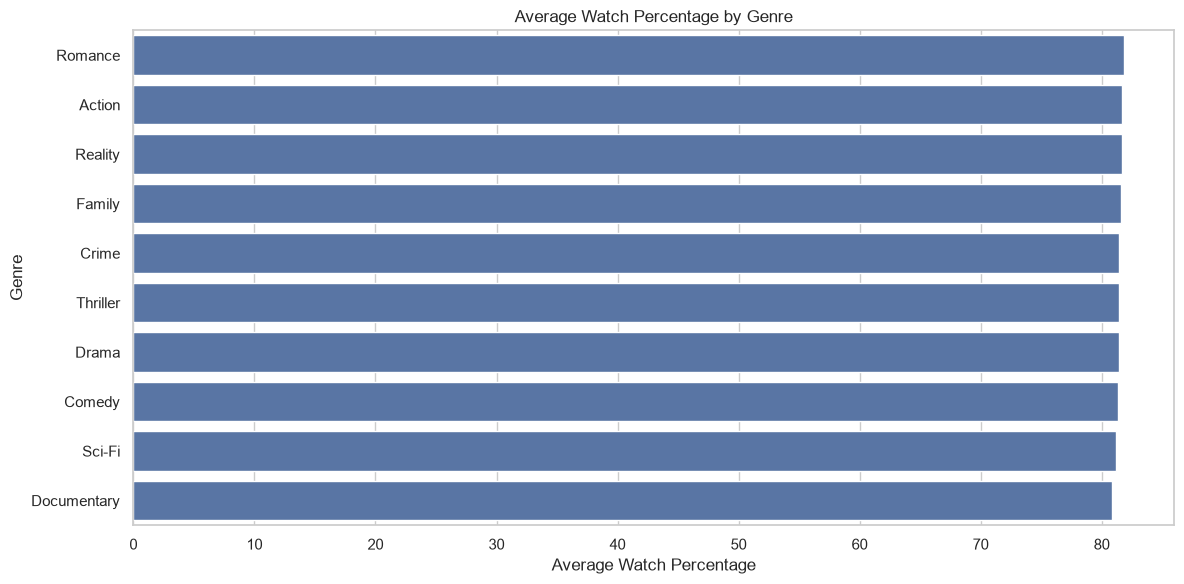

In [38]:
# graph
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_watch.values,
    y=genre_watch.index
)

plt.title("Average Watch Percentage by Genre")
plt.xlabel("Average Watch Percentage")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [39]:
df.groupby("genre")["avg_watch_percentage"].mean()

genre
Action         81.684379
Comedy         81.353477
Crime          81.463572
Documentary    80.842016
Drama          81.426632
Family         81.610469
Reality        81.658972
Romance        81.876901
Sci-Fi         81.137973
Thriller       81.439322
Name: avg_watch_percentage, dtype: float64

In [40]:
# episode drop-off analysis
drop_mapping = {
    "yes": 1,
    "true": 1,
    "1": 1,
    "no": 0,
    "false": 0,
    "0": 0
}

df["drop_off_binary"] = (
    df["drop_off"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(drop_mapping)
)

print(df["drop_off_binary"].value_counts(dropna=False))

drop_off_binary
0    31697
1     1503
Name: count, dtype: int64


In [41]:
# drop-off rate by episode number
episode_dropoff = (
    df.groupby("episode_number")["drop_off_binary"]
    .mean() * 100
)

print(episode_dropoff)

episode_number
1     5.20
2     3.95
3     4.35
4     4.10
5     5.30
6     4.05
7     4.40
8     4.20
9     4.95
10    4.50
11    4.90
12    5.40
13    4.80
14    4.05
15    4.25
16    4.20
17    4.25
Name: drop_off_binary, dtype: float64


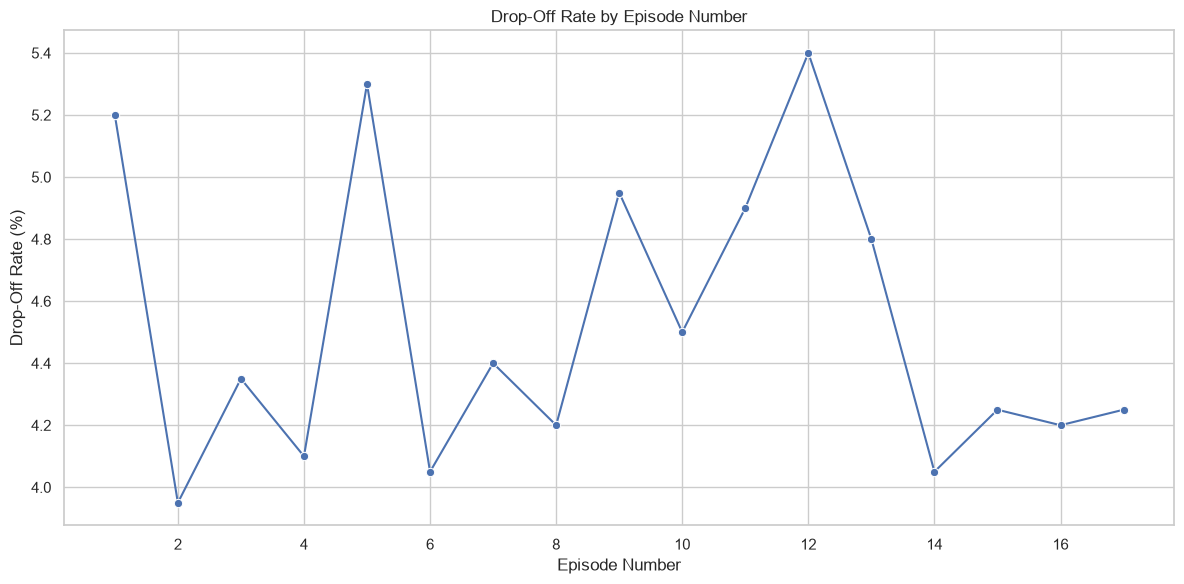

In [42]:
# graph
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=episode_dropoff.index,
    y=episode_dropoff.values,
    marker="o"
)

plt.title("Drop-Off Rate by Episode Number")
plt.xlabel("Episode Number")
plt.ylabel("Drop-Off Rate (%)")

plt.tight_layout()
plt.show()

In [43]:
# retention Risk analysis
# iski count
print(
    df["retention_risk"].value_counts()
)

retention_risk
Low       33057
Medium      141
High          2
Name: count, dtype: int64


In [44]:
# retention risk percentage
retention_percentage = (
    df["retention_risk"]
    .value_counts(normalize=True) * 100
)

print(retention_percentage.round(2))


retention_risk
Low       99.57
Medium     0.42
High       0.01
Name: proportion, dtype: float64


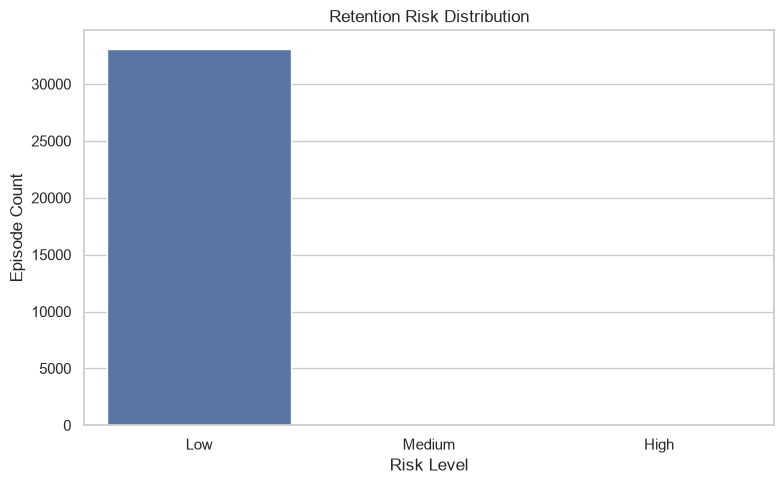

In [45]:
# chart risk
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="retention_risk",
    order=["Low", "Medium", "High"]
)

plt.title("Retention Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Episode Count")

plt.tight_layout()
plt.show()

In [46]:
# high risk episodes
high_risk = df[
    df["retention_risk"]
    .astype(str)
    .str.lower()
    .eq("high")
]

print("High Risk Episodes:", len(high_risk))

high_risk[
    [
        "title",
        "genre",
        "episode_number",
        "avg_watch_percentage",
        "drop_off_probability",
        "retention_risk"
    ]
].head(20)

High Risk Episodes: 2


,title,genre,episode_number,avg_watch_percentage,drop_off_probability,retention_risk
4921,Synthetic_Show_0455,Crime,8,36.72,0.7662,High
26860,Synthetic_Show_0870,Romance,1,35.43,0.6784,High


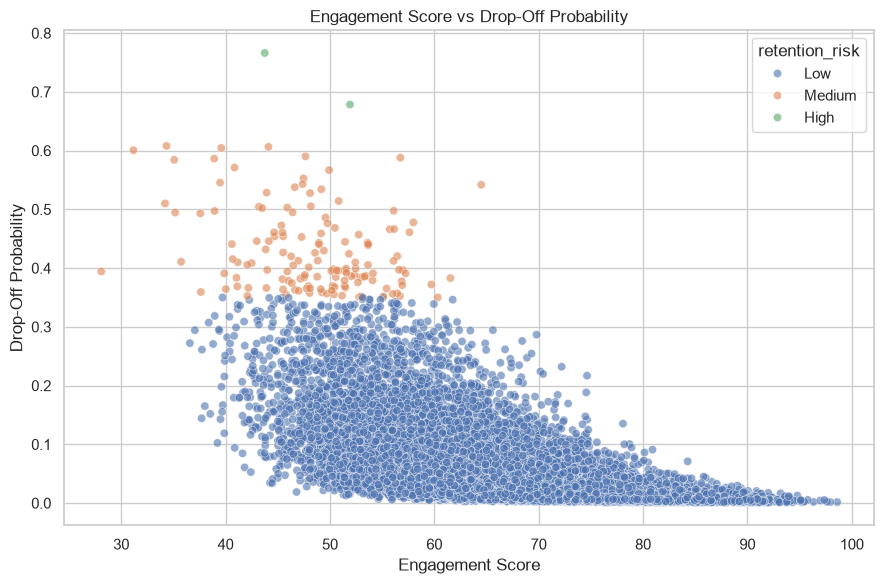

In [47]:
# Engagement VS Drop-off
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="engagement_score",
    y="drop_off_probability",
    hue="retention_risk",
    alpha=0.6
)

plt.title("Engagement Score vs Drop-Off Probability")
plt.xlabel("Engagement Score")
plt.ylabel("Drop-Off Probability")

plt.tight_layout()
plt.show()

In [48]:
# correlation
correlation = df[
    [
        "engagement_score",
        "drop_off_probability"
    ]
].corr()

print(correlation)

                      engagement_score  drop_off_probability
engagement_score              1.000000             -0.620112
drop_off_probability         -0.620112              1.000000


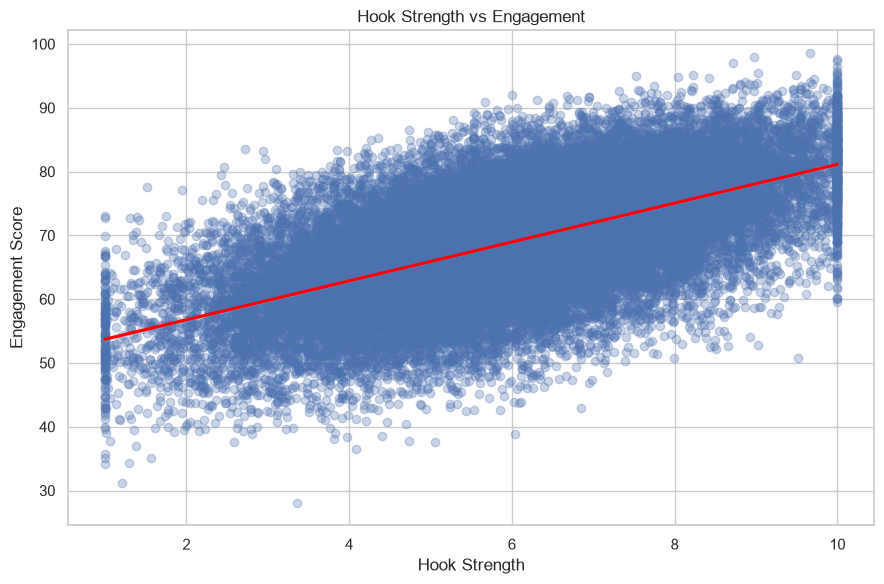

In [49]:
# Hook strength VS Viwer engagemnet
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="hook_strength",
    y="engagement_score",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Hook Strength vs Engagement")
plt.xlabel("Hook Strength")
plt.ylabel("Engagement Score")

plt.tight_layout()
plt.show()

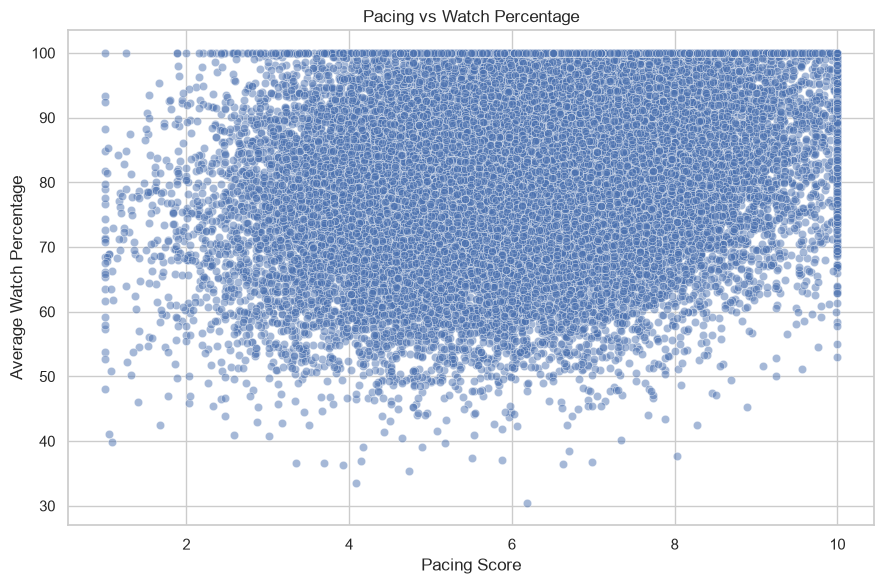

In [50]:
# pacing VS watch percentage
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="pacing_score",
    y="avg_watch_percentage",
    alpha=0.5
)

plt.title("Pacing vs Watch Percentage")
plt.xlabel("Pacing Score")
plt.ylabel("Average Watch Percentage")

plt.tight_layout()
plt.show()

In [51]:
# pacing group analysis
df["pacing_group"] = pd.cut(
    df["pacing_score"],
    bins=3,
    labels=["Low Pacing", "Medium Pacing", "High Pacing"]
)

pacing_analysis = (
    df.groupby("pacing_group", observed=True)
    ["avg_watch_percentage"]
    .mean()
)

print(pacing_analysis)

pacing_group
Low Pacing       76.054524
Medium Pacing    80.629303
High Pacing      84.641833
Name: avg_watch_percentage, dtype: float64


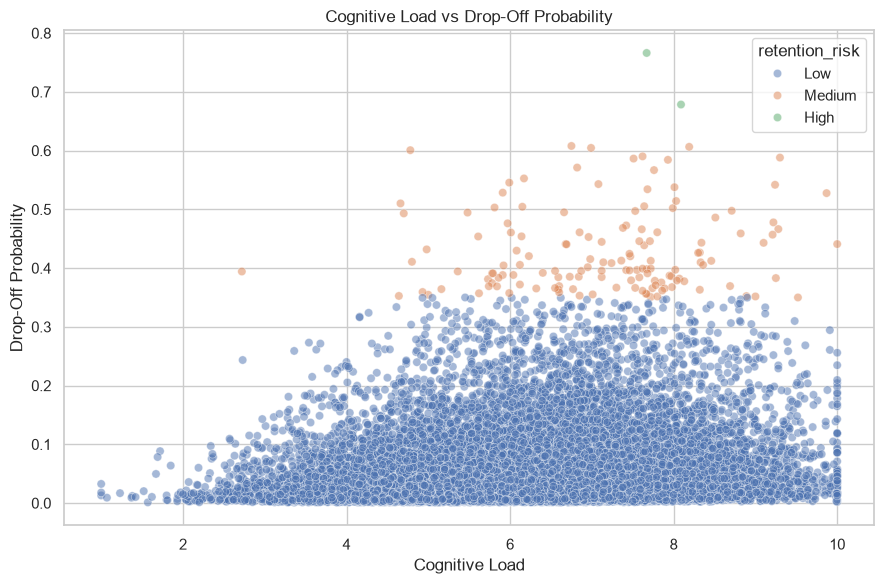

In [52]:
# congnitive load analysis
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="cognitive_load",
    y="drop_off_probability",
    hue="retention_risk",
    alpha=0.5
)

plt.title("Cognitive Load vs Drop-Off Probability")
plt.xlabel("Cognitive Load")
plt.ylabel("Drop-Off Probability")

plt.tight_layout()
plt.show()

In [53]:
# cognitive load groups
df["cognitive_group"] = pd.cut(
    df["cognitive_load"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

cognitive_analysis = (
    df.groupby("cognitive_group", observed=True)
    .agg(
        avg_watch_percentage=(
            "avg_watch_percentage", "mean"
        ),
        avg_dropoff_probability=(
            "drop_off_probability", "mean"
        ),
        avg_engagement=(
            "engagement_score", "mean"
        )
    )
)

print(cognitive_analysis)

                 avg_watch_percentage  avg_dropoff_probability  avg_engagement
cognitive_group                                                               
Low                         79.532176                 0.032145       63.759977
Medium                      81.676200                 0.039692       68.403107
High                        81.290501                 0.057014       71.359206


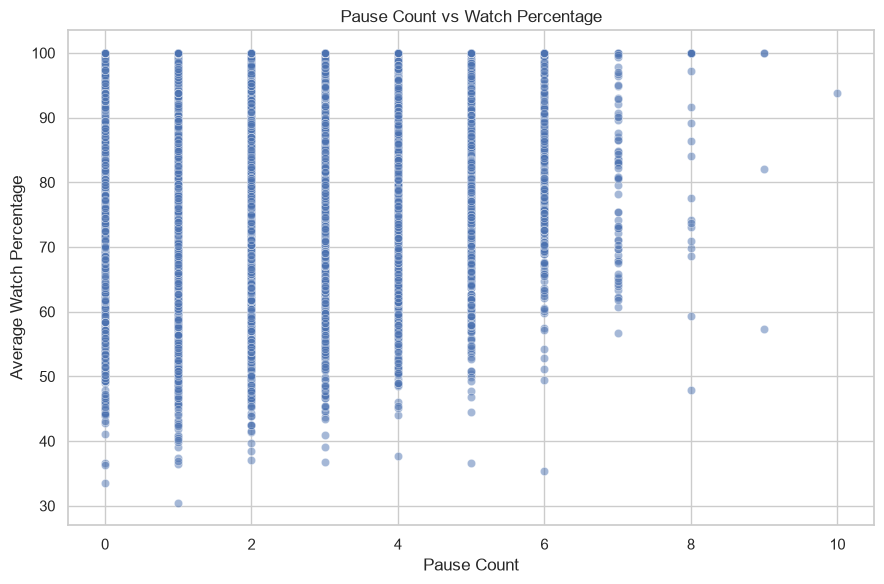

In [54]:
# pause VS waatch percentage
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="pause_count",
    y="avg_watch_percentage",
    alpha=0.5
)

plt.title("Pause Count vs Watch Percentage")
plt.xlabel("Pause Count")
plt.ylabel("Average Watch Percentage")

plt.tight_layout()
plt.show()

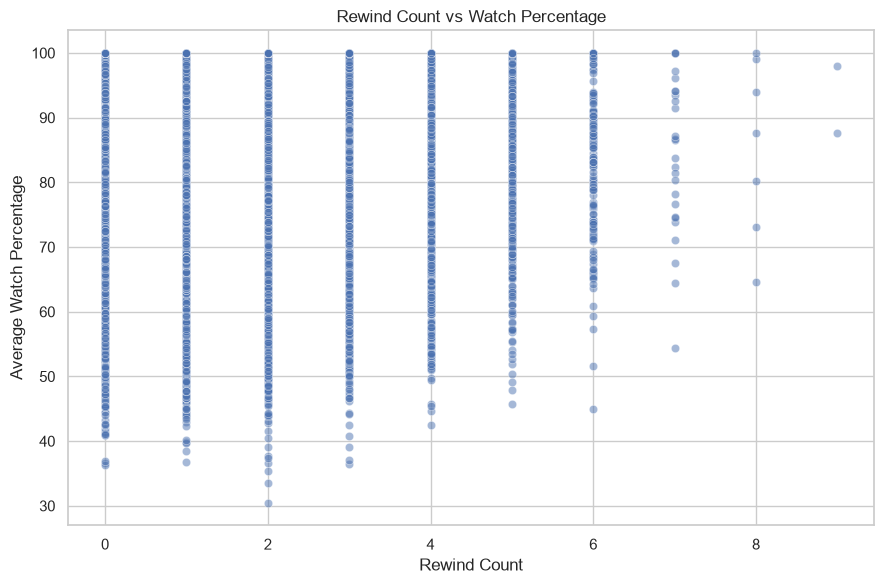

In [55]:
# rewind VS watch percentage
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="rewind_count",
    y="avg_watch_percentage",
    alpha=0.5
)

plt.title("Rewind Count vs Watch Percentage")
plt.xlabel("Rewind Count")
plt.ylabel("Average Watch Percentage")

plt.tight_layout()
plt.show()

In [56]:
# Behaviour gp analysis
df["pause_group"] = pd.cut(
    df["pause_count"],
    bins=3,
    labels=["Low Pause", "Medium Pause", "High Pause"]
)

pause_analysis = (
    df.groupby("pause_group", observed=True)
    ["avg_watch_percentage"]
    .mean()
)

print(pause_analysis)

pause_group
Low Pause       81.458011
Medium Pause    81.543434
High Pause      80.738571
Name: avg_watch_percentage, dtype: float64


In [57]:
df["rewind_group"] = pd.cut(
    df["rewind_count"],
    bins=3,
    labels=["Low Rewind", "Medium Rewind", "High Rewind"]
)

rewind_analysis = (
    df.groupby("rewind_group", observed=True)
    ["avg_watch_percentage"]
    .mean()
)

print(rewind_analysis)

rewind_group
Low Rewind       81.322345
Medium Rewind    83.307839
High Rewind      84.781714
Name: avg_watch_percentage, dtype: float64


In [58]:
# season level analysis
season_analysis = (
    df.groupby("season_number")
    .agg(
        avg_engagement=(
            "engagement_score", "mean"
        ),
        avg_watch=(
            "avg_watch_percentage", "mean"
        ),
        avg_dropoff=(
            "drop_off_probability", "mean"
        ),
        total_episodes=(
            "episode_number", "count"
        )
    )
    .sort_values(
        by="avg_engagement",
        ascending=False
    )
)

print(season_analysis)

               avg_engagement  avg_watch  avg_dropoff  total_episodes
season_number                                                        
1                   68.968853  81.494574     0.043761           16200
2                   68.914064  81.435020     0.043949           17000


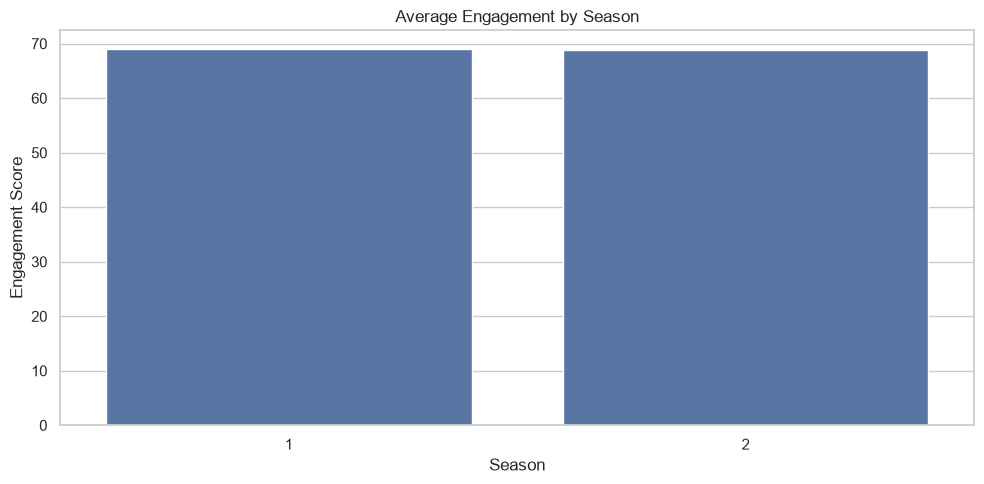

In [59]:
# season level chart 
plt.figure(figsize=(10, 5))

sns.barplot(
    data=season_analysis.reset_index(),
    x="season_number",
    y="avg_engagement"
)

plt.title("Average Engagement by Season")
plt.xlabel("Season")
plt.ylabel("Engagement Score")

plt.tight_layout()
plt.show()

In [60]:
# multi level groupby
show_season_analysis = (
    df.groupby(["title", "season_number"])
    .agg(
        avg_engagement=(
            "engagement_score", "mean"
        ),
        avg_watch=(
            "avg_watch_percentage", "mean"
        ),
        avg_dropoff=(
            "drop_off_probability", "mean"
        )
    )
    .reset_index()
)

show_season_analysis.head(10)

,title,season_number,avg_engagement,avg_watch,avg_dropoff
0,Synthetic_Show_0001,1,67.138118,81.089412,0.038312
1,Synthetic_Show_0001,2,69.278588,82.608235,0.053100
2,Synthetic_Show_0002,1,66.868706,79.330588,0.042729
3,Synthetic_Show_0002,2,68.816000,78.892941,0.044418
4,Synthetic_Show_0003,1,68.910588,80.550000,0.044035
5,Synthetic_Show_0003,2,64.421176,77.502941,0.072506
6,Synthetic_Show_0004,1,66.072706,78.670000,0.068576
7,Synthetic_Show_0004,2,66.769882,78.036471,0.042529
8,Synthetic_Show_0005,1,64.900000,78.788235,0.086629
9,Synthetic_Show_0005,2,69.108706,83.333529,0.047476


In [61]:
# top 10 episodes by engagement
top_episodes = df.nlargest(
    10, "engagement_score"
)

top_episodes[
    [
        "title",
        "genre",
        "season_number",
        "episode_number",
        "avg_watch_percentage",
        "engagement_score"
    ]
]

,title,genre,season_number,episode_number,avg_watch_percentage,engagement_score
18688,Synthetic_Show_0606,Action,1,10,100.00,98.600
27846,Synthetic_Show_0456,Comedy,1,12,100.00,97.940
31106,Synthetic_Show_0515,Family,1,1,98.31,97.624
32503,Synthetic_Show_0730,Reality,2,13,100.00,97.360
27175,Synthetic_Show_0764,Family,1,2,100.00,96.980
118,Synthetic_Show_0046,Comedy,1,1,100.00,96.340
12602,Synthetic_Show_0728,Family,1,7,100.00,95.780
8635,Synthetic_Show_0472,Family,1,2,100.00,95.480
19387,Synthetic_Show_0276,Romance,2,2,100.00,95.420
6418,Synthetic_Show_0359,Family,1,3,100.00,95.200


In [62]:
# bootom 10 episides
bottom_episodes = df.nsmallest(
    10, "engagement_score"
)

bottom_episodes[
    [
        "title",
        "genre",
        "season_number",
        "episode_number",
        "avg_watch_percentage",
        "engagement_score"
    ]
]

,title,genre,season_number,episode_number,avg_watch_percentage,engagement_score
21457,Synthetic_Show_0628,Sci-Fi,2,7,39.89,28.076
32722,Synthetic_Show_0258,Crime,1,11,36.26,31.164
22513,Synthetic_Show_0972,Action,1,3,48.84,34.196
14220,Synthetic_Show_0488,Thriller,2,1,42.49,34.336
3315,Synthetic_Show_0983,Family,2,15,50.78,35.072
27260,Synthetic_Show_0167,Family,1,17,33.50,35.160
14481,Synthetic_Show_0957,Thriller,2,17,51.89,35.736
31470,Synthetic_Show_0024,Sci-Fi,2,8,41.03,36.572
32399,Synthetic_Show_0563,Reality,2,16,52.13,37.052
10254,Synthetic_Show_0896,Crime,1,3,36.59,37.576


In [63]:
# highest drop-off probability
high_dropoff_episodes = df.nlargest(
    10, "drop_off_probability"
)

high_dropoff_episodes[
    [
        "title",
        "genre",
        "episode_number",
        "avg_watch_percentage",
        "drop_off_probability",
        "retention_risk"
    ]
]

,title,genre,episode_number,avg_watch_percentage,drop_off_probability,retention_risk
4921,Synthetic_Show_0455,Crime,8,36.72,0.7662,High
26860,Synthetic_Show_0870,Romance,1,35.43,0.6784,High
14220,Synthetic_Show_0488,Thriller,1,42.49,0.6079,Medium
10083,Synthetic_Show_0768,Drama,16,46.01,0.6064,Medium
555,Synthetic_Show_0375,Reality,9,44.50,0.6046,Medium
32722,Synthetic_Show_0258,Crime,11,36.26,0.6007,Medium
13880,Synthetic_Show_0017,Action,15,51.98,0.5902,Medium
9734,Synthetic_Show_0593,Documentary,4,54.01,0.5881,Medium
2299,Synthetic_Show_0194,Thriller,7,40.91,0.5864,Medium
3315,Synthetic_Show_0983,Family,15,50.78,0.5843,Medium


In [64]:
# shows with highest engagement 
show_performance = (
    df.groupby("title")
    .agg(
        avg_engagement=(
            "engagement_score", "mean"
        ),
        avg_watch=(
            "avg_watch_percentage", "mean"
        ),
        episode_count=(
            "episode_number", "count"
        )
    )
)

show_performance = show_performance[
    show_performance["episode_count"] >= 5
]

show_performance = show_performance.sort_values(
    by="avg_engagement",
    ascending=False
)

show_performance.head(10)

,avg_engagement,avg_watch,episode_count
title,,,
Synthetic_Show_0492,73.734788,86.790000,33
Synthetic_Show_0613,73.618182,89.533333,33
Synthetic_Show_0122,73.416706,84.806471,34
Synthetic_Show_0045,73.370118,85.354706,34
Synthetic_Show_0409,73.324485,85.079394,33
Synthetic_Show_0863,73.317333,86.579697,33
Synthetic_Show_0723,73.102182,86.816061,33
Synthetic_Show_0036,73.052824,86.835000,34
Synthetic_Show_0318,72.778182,86.633333,33


In [65]:
# correlation analysis
correlation_columns = [
    "episode_duration_min",
    "pacing_score",
    "hook_strength",
    "dialogue_density",
    "visual_intensity",
    "avg_watch_percentage",
    "pause_count",
    "rewind_count",
    "cognitive_load",
    "drop_off_probability",
    "engagement_score"
]

available_columns = [
    col for col in correlation_columns
    if col in df.columns
]

correlation_matrix = df[
    available_columns
].corr()

print(correlation_matrix.round(2))

                      episode_duration_min  pacing_score  hook_strength  \
episode_duration_min                  1.00          0.00           0.01   
pacing_score                          0.00          1.00           0.00   
hook_strength                         0.01          0.00           1.00   
dialogue_density                     -0.01         -0.01           0.00   
visual_intensity                     -0.01          0.00           0.00   
avg_watch_percentage                 -0.12          0.24           0.40   
pause_count                          -0.00          0.09          -0.01   
rewind_count                         -0.00          0.01           0.17   
cognitive_load                       -0.01          0.31           0.00   
drop_off_probability                  0.13         -0.21          -0.49   
engagement_score                     -0.06          0.49           0.61   

                      dialogue_density  visual_intensity  \
episode_duration_min             -0.01 

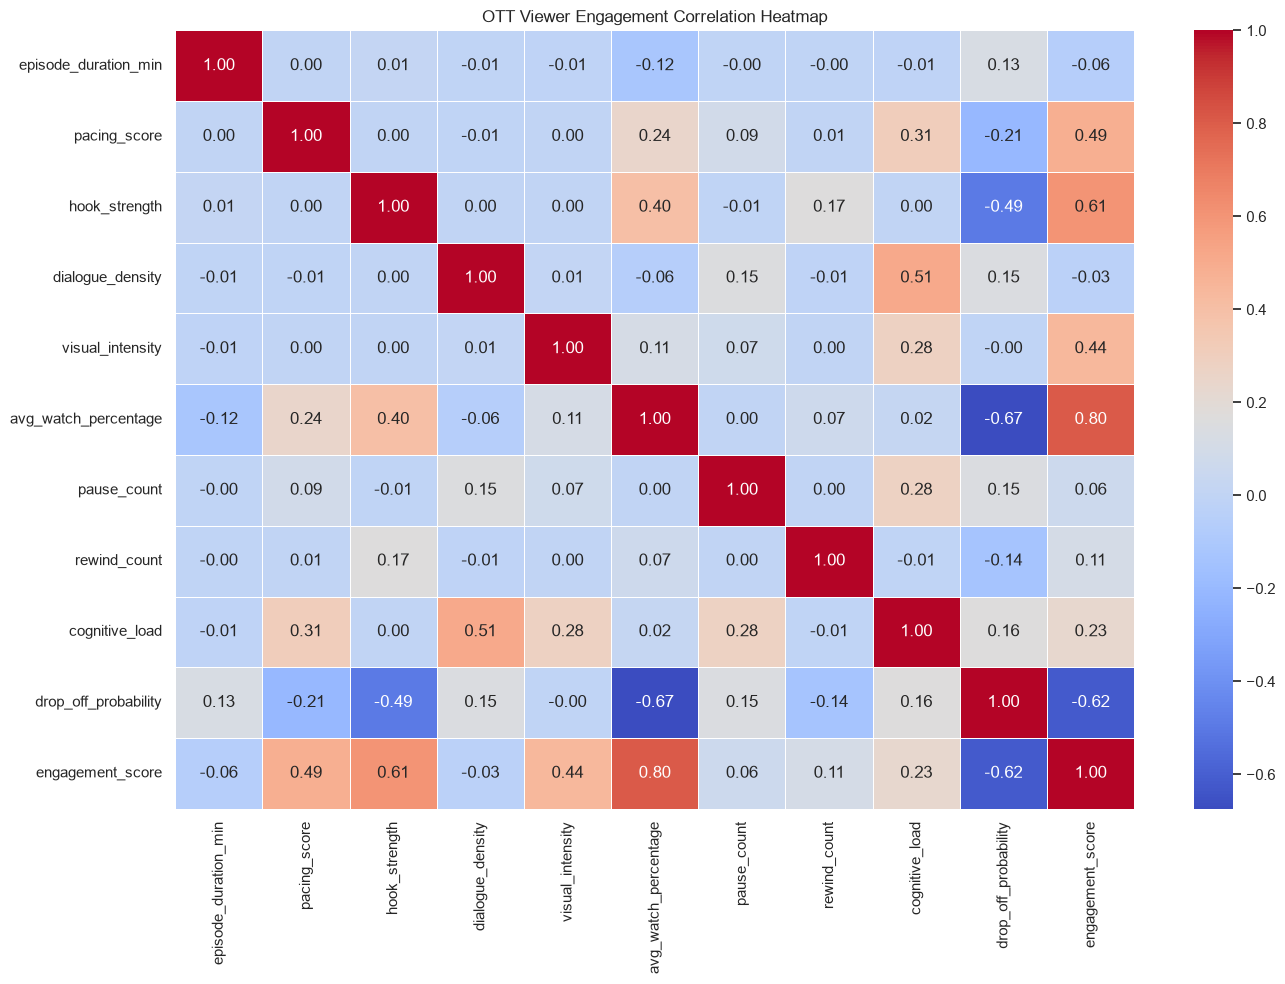

In [66]:
# correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("OTT Viewer Engagement Correlation Heatmap")

plt.tight_layout()
plt.show()

In [67]:
# intro skip analysis
print(df["skip_intro"].value_counts())

skip_intro
Yes    22747
No     10453
Name: count, dtype: int64


In [68]:
# genre-wise intro skip rate
df["skip_intro_clean"] = (
    df["skip_intro"]
    .astype(str)
    .str.lower()
    .str.strip()
    .map({
        "yes": 1,
        "true": 1,
        "1": 1,
        "no": 0,
        "false": 0,
        "0": 0
    })
)

In [69]:
# genre-wise percentage
intro_analysis = (
    df.groupby("genre")["skip_intro_clean"]
    .mean() * 100
)

intro_analysis = intro_analysis.sort_values(
    ascending=False
)

print(intro_analysis)

genre
Family         69.431500
Thriller       69.253082
Reality        69.194188
Crime          68.887601
Action         68.684877
Comedy         68.331473
Sci-Fi         68.183161
Romance        68.004723
Documentary    67.792876
Drama          67.332340
Name: skip_intro_clean, dtype: float64


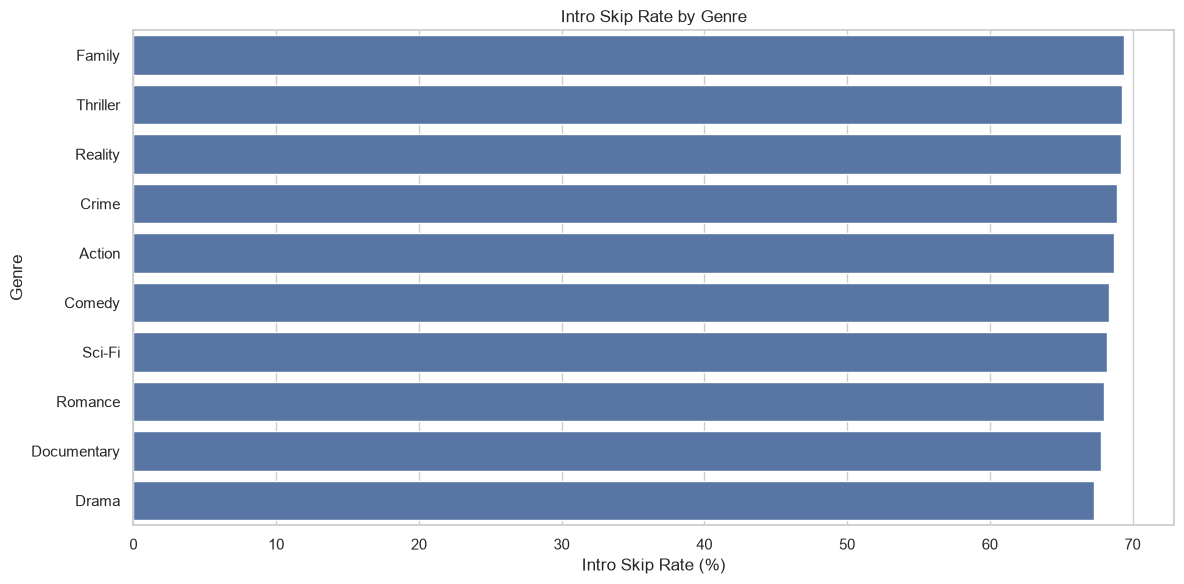

In [70]:
# graph
plt.figure(figsize=(12, 6))

sns.barplot(
    x=intro_analysis.values,
    y=intro_analysis.index
)

plt.title("Intro Skip Rate by Genre")
plt.xlabel("Intro Skip Rate (%)")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

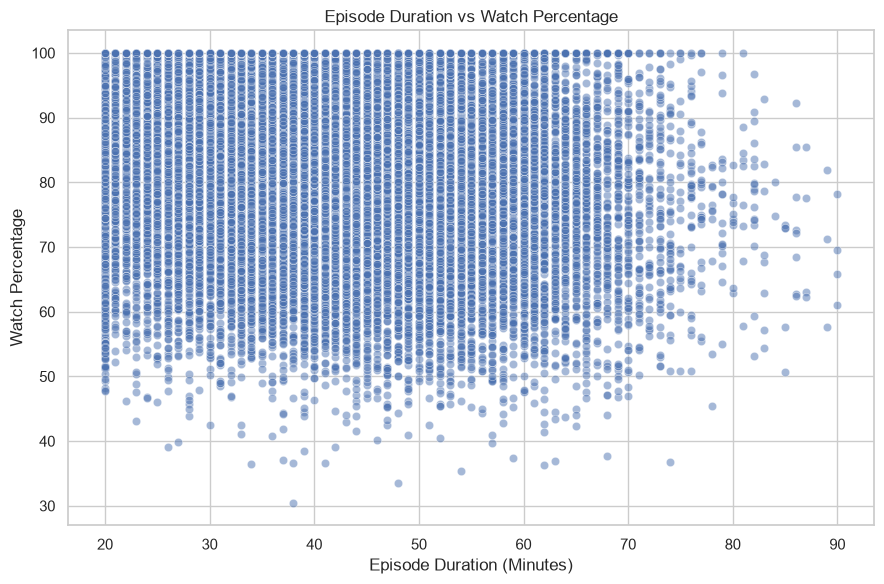

In [71]:
# episode duration VS watch percentage
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="episode_duration_min",
    y="avg_watch_percentage",
    alpha=0.5
)

plt.title("Episode Duration vs Watch Percentage")
plt.xlabel("Episode Duration (Minutes)")
plt.ylabel("Watch Percentage")

plt.tight_layout()
plt.show()

In [72]:
# duration groups
df["duration_group"] = pd.cut(
    df["episode_duration_min"],
    bins=[0, 20, 40, 60, 90, float("inf")],
    labels=[
        "0-20 min",
        "20-40 min",
        "40-60 min",
        "60-90 min",
        "90+ min"
    ]
)

duration_analysis = (
    df.groupby("duration_group", observed=True)
    .agg(
        avg_watch_percentage=(
            "avg_watch_percentage", "mean"
        ),
        avg_engagement=(
            "engagement_score", "mean"
        ),
        avg_dropoff=(
            "drop_off_probability", "mean"
        ),
        episode_count=(
            "title", "count"
        )
    )
)

print(duration_analysis)

                avg_watch_percentage  avg_engagement  avg_dropoff  \
duration_group                                                      
0-20 min                   82.471993       69.240498     0.038454   
20-40 min                  82.684467       69.404726     0.038203   
40-60 min                  80.893625       68.725967     0.046065   
60-90 min                  77.432306       67.458201     0.065772   

                episode_count  
duration_group                 
0-20 min                 1846  
20-40 min               13709  
40-60 min               15182  
60-90 min                2463  


In [73]:
# high risk episodes ki characteristics
high_risk_features = [
    "avg_watch_percentage",
    "episode_duration_min",
    "hook_strength",
    "pacing_score",
    "visual_intensity",
    "cognitive_load",
    "pause_count",
    "rewind_count",
    "drop_off_probability",
    "engagement_score"
]

available_features = [
    col for col in high_risk_features
    if col in df.columns
]

risk_comparison = (
    df.groupby("retention_risk")[available_features]
    .mean()
)

print(risk_comparison.round(2))

                avg_watch_percentage  episode_duration_min  hook_strength  \
retention_risk                                                              
High                           36.08                 64.00           4.10   
Low                            81.59                 41.77           6.01   
Medium                         52.20                 48.73           2.76   

                pacing_score  visual_intensity  cognitive_load  pause_count  \
retention_risk                                                                
High                    5.86              6.74            7.88         4.50   
Low                     6.20              5.99            6.17         1.66   
Medium                  4.87              6.09            7.15         2.58   

                rewind_count  drop_off_probability  engagement_score  
retention_risk                                                        
High                    1.50                  0.72             47.83  
Low  

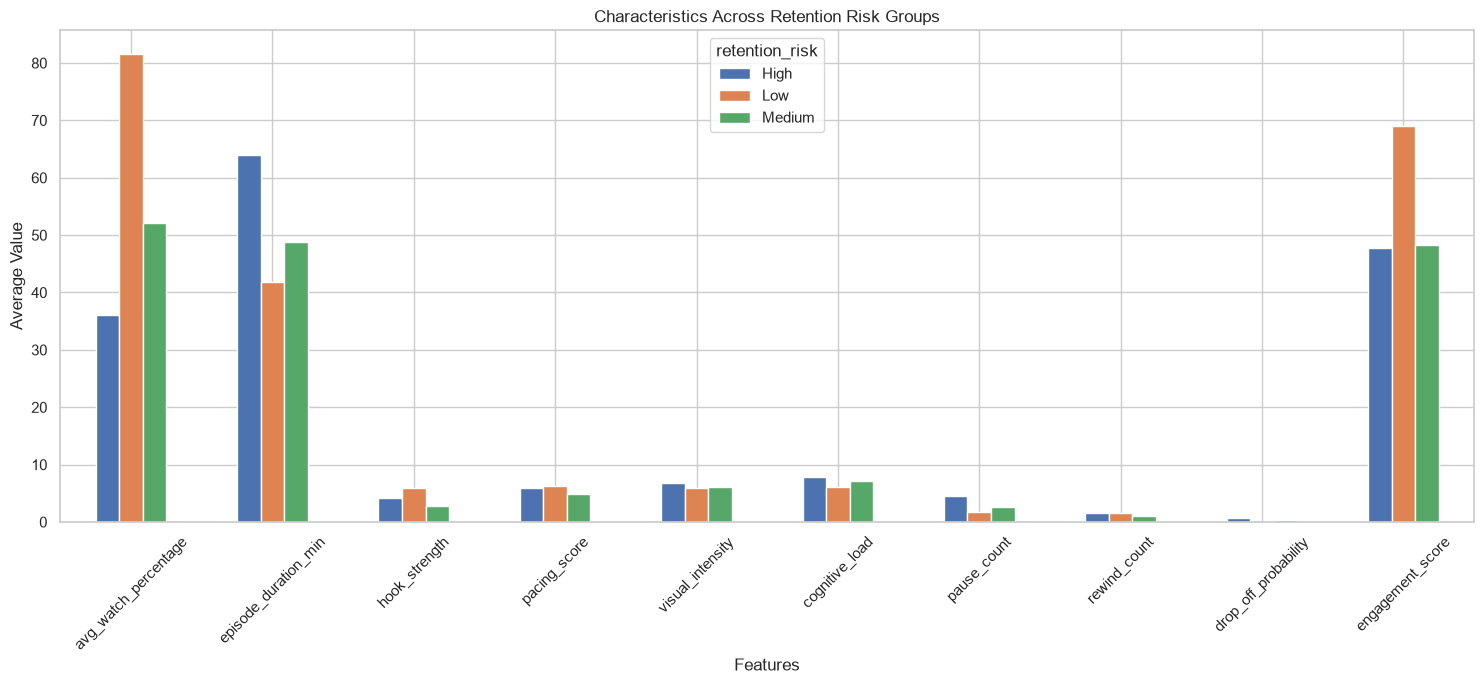

In [74]:
# graph
risk_comparison.T.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Characteristics Across Retention Risk Groups")
plt.xlabel("Features")
plt.ylabel("Average Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [75]:
# high engaged episodes ki characteristics
engagement_threshold = df["engagement_score"].quantile(0.75)

high_engagement = df[
    df["engagement_score"] >= engagement_threshold
]

low_engagement = df[
    df["engagement_score"] < engagement_threshold
]

comparison = pd.DataFrame({
    "High Engagement": high_engagement[
        available_features
    ].mean(),

    "Other Episodes": low_engagement[
        available_features
    ].mean()
})

print(comparison.round(2))

                      High Engagement  Other Episodes
avg_watch_percentage            93.33           77.51
episode_duration_min            40.98           42.07
hook_strength                    7.44            5.51
pacing_score                     7.23            5.84
visual_intensity                 6.99            5.66
cognitive_load                   6.56            6.04
pause_count                      1.78            1.63
rewind_count                     1.68            1.46
drop_off_probability             0.01            0.05
engagement_score                80.66           65.04


In [76]:
# shows with consistently high engagement 
consistency_analysis = (
    df.groupby("title")
    .agg(
        avg_engagement=(
            "engagement_score", "mean"
        ),
        engagement_std=(
            "engagement_score", "std"
        ),
        min_engagement=(
            "engagement_score", "min"
        ),
        max_engagement=(
            "engagement_score", "max"
        ),
        episode_count=(
            "episode_number", "count"
        )
    )
)

consistency_analysis = consistency_analysis[
    consistency_analysis["episode_count"] >= 5
]

consistency_analysis = consistency_analysis.sort_values(
    by=["avg_engagement", "engagement_std"],
    ascending=[False, True]
)

consistency_analysis.head(10)

,avg_engagement,engagement_std,min_engagement,max_engagement,episode_count
title,,,,,
Synthetic_Show_0492,73.734788,10.543747,52.412,93.172,33
Synthetic_Show_0613,73.618182,7.077622,59.164,86.612,33
Synthetic_Show_0122,73.416706,10.945507,42.284,89.880,34
Synthetic_Show_0045,73.370118,7.452209,54.268,89.960,34
Synthetic_Show_0409,73.324485,8.664836,54.536,89.300,33
Synthetic_Show_0863,73.317333,8.909925,55.168,90.720,33
Synthetic_Show_0723,73.102182,10.235567,42.332,86.920,33
Synthetic_Show_0036,73.052824,8.805733,54.076,90.380,34
Synthetic_Show_0318,72.778182,7.624472,56.940,85.860,33


In [77]:
# high risk shows identify karna 
high_risk_shows = (
    df.assign(
        high_risk_flag=(
            df["retention_risk"]
            .astype(str)
            .str.lower()
            .eq("high")
        )
    )
    .groupby("title")
    .agg(
        total_episodes=(
            "episode_number", "count"
        ),
        high_risk_episodes=(
            "high_risk_flag", "sum"
        ),
        avg_watch=(
            "avg_watch_percentage", "mean"
        ),
        avg_engagement=(
            "engagement_score", "mean"
        )
    )
)

high_risk_shows["high_risk_percentage"] = (
    high_risk_shows["high_risk_episodes"]
    / high_risk_shows["total_episodes"] * 100
)

high_risk_shows = high_risk_shows.sort_values(
    "high_risk_percentage",
    ascending=False
)

high_risk_shows.head(10)

,total_episodes,high_risk_episodes,avg_watch,avg_engagement,high_risk_percentage
title,,,,,
Synthetic_Show_0870,33,1,82.606364,71.002545,3.030303
Synthetic_Show_0455,33,1,84.291818,72.238545,3.030303
Synthetic_Show_0471,33,0,81.441212,68.141333,0.000000
Synthetic_Show_0726,33,0,79.849697,68.593818,0.000000
Synthetic_Show_0919,33,0,80.563333,68.333818,0.000000
Synthetic_Show_0951,33,0,78.547273,67.567394,0.000000
Synthetic_Show_0967,33,0,82.775152,69.254303,0.000000
Synthetic_Show_0979,33,0,81.810303,69.247152,0.000000
Synthetic_Show_0981,33,0,81.251515,69.120606,0.000000


In [78]:
# content promotion priority
promotion_candidates = df[
    (df["engagement_score"] >=
     df["engagement_score"].quantile(0.75))
    &
    (df["avg_watch_percentage"] >= 70)
    &
    (
        df["retention_risk"]
        .astype(str)
        .str.lower() == "low"
    )
]

promotion_candidates = promotion_candidates.sort_values(
    by="engagement_score",
    ascending=False
)

promotion_candidates[
    [
        "title",
        "genre",
        "season_number",
        "episode_number",
        "avg_watch_percentage",
        "engagement_score",
        "retention_risk"
    ]
].head(20)

,title,genre,season_number,episode_number,avg_watch_percentage,engagement_score,retention_risk
18688,Synthetic_Show_0606,Action,1,10,100.00,98.600,Low
27846,Synthetic_Show_0456,Comedy,1,12,100.00,97.940,Low
31106,Synthetic_Show_0515,Family,1,1,98.31,97.624,Low
32503,Synthetic_Show_0730,Reality,2,13,100.00,97.360,Low
27175,Synthetic_Show_0764,Family,1,2,100.00,96.980,Low
118,Synthetic_Show_0046,Comedy,1,1,100.00,96.340,Low
12602,Synthetic_Show_0728,Family,1,7,100.00,95.780,Low
8635,Synthetic_Show_0472,Family,1,2,100.00,95.480,Low
19387,Synthetic_Show_0276,Romance,2,2,100.00,95.420,Low
6418,Synthetic_Show_0359,Family,1,3,100.00,95.200,Low


In [79]:
# episodes requiring investigation
investigation_candidates = df[
    (
        df["retention_risk"]
        .astype(str)
        .str.lower() == "high"
    )
    |
    (
        df["drop_off_probability"] >=
        df["drop_off_probability"].quantile(0.90)
    )
]

investigation_candidates = investigation_candidates.sort_values(
    by="drop_off_probability",
    ascending=False
)

investigation_candidates[
    [
        "title",
        "genre",
        "season_number",
        "episode_number",
        "episode_duration_min",
        "hook_strength",
        "pacing_score",
        "avg_watch_percentage",
        "drop_off_probability",
        "retention_risk"
    ]
].head(20)

,title,genre,season_number,episode_number,episode_duration_min,hook_strength,pacing_score,avg_watch_percentage,drop_off_probability,retention_risk
4921,Synthetic_Show_0455,Crime,1,8,74,2.11,6.99,36.72,0.7662,High
26860,Synthetic_Show_0870,Romance,1,1,54,6.10,4.73,35.43,0.6784,High
14220,Synthetic_Show_0488,Thriller,2,1,33,1.30,1.67,42.49,0.6079,Medium
10083,Synthetic_Show_0768,Drama,1,16,58,1.67,6.60,46.01,0.6064,Medium
555,Synthetic_Show_0375,Reality,1,9,39,2.79,3.45,44.50,0.6046,Medium
32722,Synthetic_Show_0258,Crime,1,11,62,1.21,3.92,36.26,0.6007,Medium
13880,Synthetic_Show_0017,Action,1,15,59,1.21,4.20,51.98,0.5902,Medium
9734,Synthetic_Show_0593,Documentary,1,4,62,4.90,3.44,54.01,0.5881,Medium
2299,Synthetic_Show_0194,Thriller,2,7,49,6.04,2.59,40.91,0.5864,Medium
3315,Synthetic_Show_0983,Family,2,15,51,1.00,2.44,50.78,0.5843,Medium


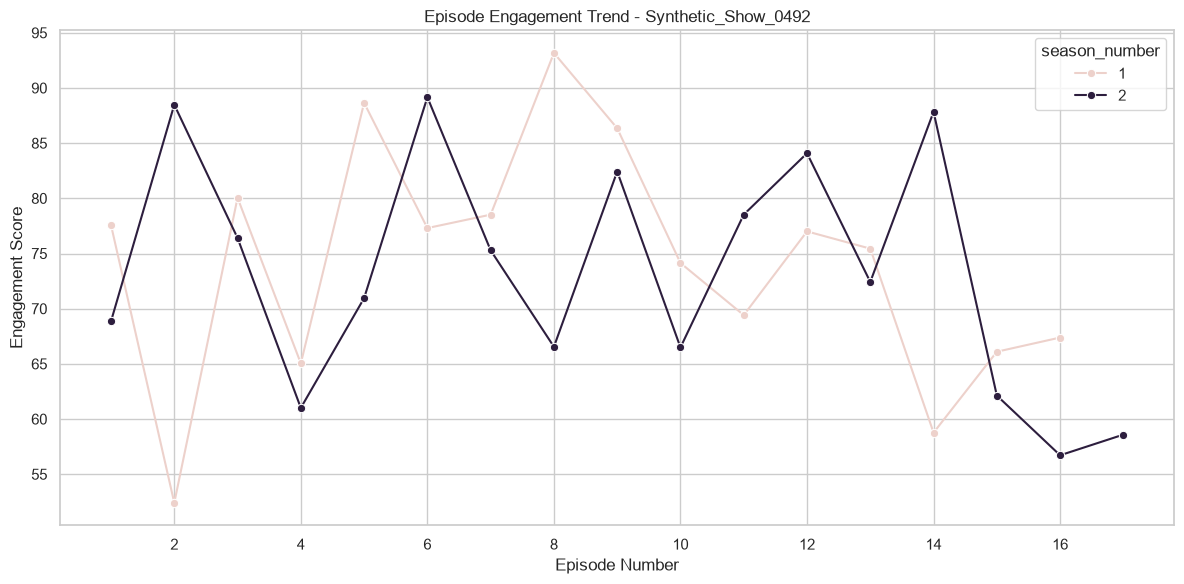

In [80]:
# advanced analysis
top_show = consistency_analysis.index[0]

show_data = df[
    df["title"] == top_show
].sort_values(
    ["season_number", "episode_number"]
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=show_data,
    x="episode_number",
    y="engagement_score",
    hue="season_number",
    marker="o"
)

plt.title(f"Episode Engagement Trend - {top_show}")
plt.xlabel("Episode Number")
plt.ylabel("Engagement Score")

plt.tight_layout()
plt.show()

In [81]:
# final business insights
print("=" * 55)
print("OTT VIEWER ENGAGEMENT ANALYSIS")
print("=" * 55)

print("\n1. Total Episodes:", len(df))

print(
    "\n2. Average Watch Percentage:",
    round(df["avg_watch_percentage"].mean(), 2)
)

print(
    "\n3. Average Engagement Score:",
    round(df["engagement_score"].mean(), 2)
)

print(
    "\n4. Highest Engagement Genre:",
    genre_engagement.idxmax()
)

print(
    "\n5. Highest Watch Percentage Genre:",
    genre_watch.idxmax()
)

print(
    "\n6. Highest Engagement Show:",
    show_performance.index[0]
)

print(
    "\n7. High Retention Risk Episodes:",
    len(high_risk)
)

print(
    "\n8. High Risk Percentage:",
    round(len(high_risk) / len(df) * 100, 2),
    "%"
)

print(
    "\n9. Promotion Candidates:",
    len(promotion_candidates)
)

print(
    "\n10. Investigation Candidates:",
    len(investigation_candidates)
)

print("\nAnalysis Completed Successfully!")

OTT VIEWER ENGAGEMENT ANALYSIS

1. Total Episodes: 33200

2. Average Watch Percentage: 81.46

3. Average Engagement Score: 68.94

4. Highest Engagement Genre: Romance

5. Highest Watch Percentage Genre: Romance

6. Highest Engagement Show: Synthetic_Show_0492

7. High Retention Risk Episodes: 2

8. High Risk Percentage: 0.01 %

9. Promotion Candidates: 8292

10. Investigation Candidates: 3326

Analysis Completed Successfully!


In [82]:
# check unique shows and episodes
print("Unique Shows:", df["show_id"].nunique())

print("Unique Titles:", df["title"].nunique())

print("Unique Genres:", df["genre"].nunique())

print("Unique Platforms:", df["platform"].nunique())

Unique Shows: 1000
Unique Titles: 1000
Unique Genres: 10
Unique Platforms: 4


In [83]:
# check episoded level duplication keys
episode_key = [
    "show_id",
    "season_number",
    "episode_number"
]

print(
    "Duplicate Episode Keys:",
    df.duplicated(subset=episode_key).sum()
)

Duplicate Episode Keys: 0


In [84]:
# probability scale validation 
print(
    df["drop_off_probability"].describe()
)

count    33200.000000
mean         0.043858
std          0.055309
min          0.000500
25%          0.011800
50%          0.024900
75%          0.053200
max          0.766200
Name: drop_off_probability, dtype: float64


In [85]:
# 0-1 scale 
if df["drop_off_probability"].max() > 1:
    df["drop_off_probability_normalized"] = (
        df["drop_off_probability"] / 100
    )
else:
    df["drop_off_probability_normalized"] = (
        df["drop_off_probability"]
    )

In [86]:
# watch percentage validation 
invalid_watch = df[
    (df["avg_watch_percentage"] < 0) |
    (df["avg_watch_percentage"] > 100)
]

print("Invalid Watch Percentage Records:", len(invalid_watch))

Invalid Watch Percentage Records: 0


In [87]:
# episodes duration validation
invalid_duration = df[
    df["episode_duration_min"] <= 0
]

print("Invalid Duration Records:", len(invalid_duration))

Invalid Duration Records: 0


In [88]:
# export result protfolio ready
os.makedirs("outputs/charts", exist_ok=True)

os.makedirs("outputs/reports", exist_ok=True)

In [89]:
# save analysis rsults
top_episodes.to_csv(
    "outputs/reports/top_10_episodes.csv",
    index=False
)

bottom_episodes.to_csv(
    "outputs/reports/bottom_10_episodes.csv",
    index=False
)

high_risk.to_csv(
    "outputs/reports/high_risk_episodes.csv",
    index=False
)

promotion_candidates.to_csv(
    "outputs/reports/promotion_candidates.csv",
    index=False
)

investigation_candidates.to_csv(
    "outputs/reports/investigation_candidates.csv",
    index=False
)

show_performance.to_csv(
    "outputs/reports/show_performance.csv"
)

print("All reports exported successfully!")

All reports exported successfully!


In [90]:
# final clean dataset
df.to_csv(
    "outputs/reports/cleaned_ott_dataset.csv",
    index=False
)

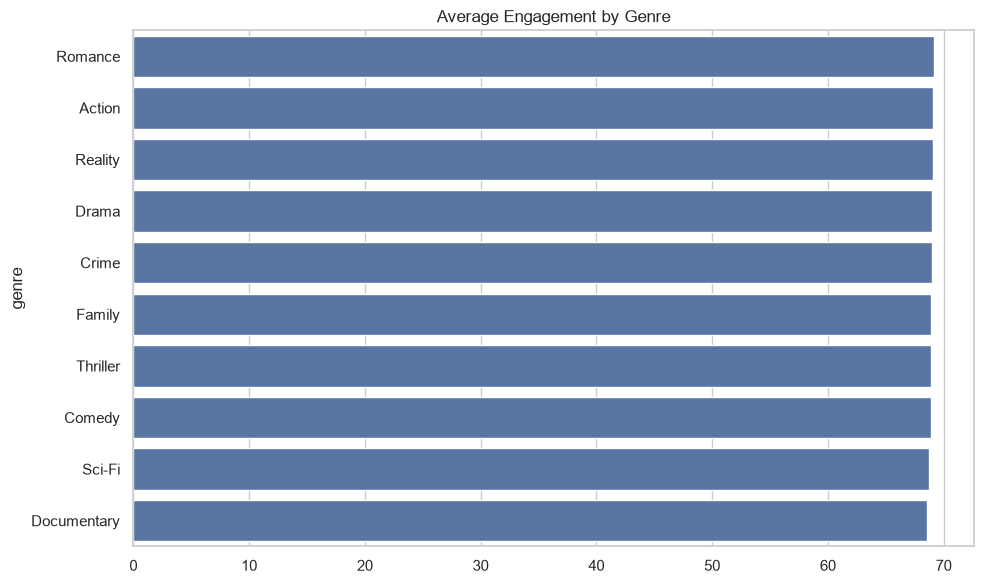

In [91]:
# save a chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_engagement.values,
    y=genre_engagement.index
)

plt.title("Average Engagement by Genre")

plt.tight_layout()

plt.savefig(
    "outputs/charts/genre_engagement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [93]:

# FINAL PROJECT SUMMARY

import os
import pandas as pd
import numpy as np

# Create report folder
os.makedirs("outputs/reports", exist_ok=True)

# Convert drop_off into numeric format
drop_off_numeric = (
    df["drop_off"]
    .replace({"Yes": 1, "No": 0})
)

drop_off_numeric = pd.to_numeric(
    drop_off_numeric,
    errors="coerce"
)

# Overall business metrics
total_episodes = len(df)

average_watch = df["avg_watch_percentage"].mean()

overall_drop_off = drop_off_numeric.mean() * 100

# Genre-wise analysis
final_summary = df.assign(
    drop_off_numeric=drop_off_numeric
).groupby("genre").agg(
    Average_Watch_Percentage=("avg_watch_percentage", "mean"),
    Average_Drop_Off=("drop_off_numeric", "mean"),
    Total_Episodes=("show_id", "count")
).reset_index()

final_summary["Average_Drop_Off"] *= 100

# Display results
print("========== OTT PROJECT SUMMARY ==========")

print("Total Episodes:", total_episodes)

print("Average Watch Percentage:",
      round(average_watch, 2), "%")

print("Overall Drop-Off Rate:",
      round(overall_drop_off, 2), "%")

print("\n========== GENRE-WISE BUSINESS INSIGHTS ==========")

display(final_summary)

# Save final report
final_summary.to_csv(
    "outputs/reports/genre_business_summary.csv",
    index=False
)

print("\nFinal Business Report Saved Successfully!")


========== OTT PROJECT SUMMARY ==========
Total Episodes: 33200
Average Watch Percentage: 81.46 %
Overall Drop-Off Rate: 4.53 %

========== GENRE-WISE BUSINESS INSIGHTS ==========


,genre,Average_Watch_Percentage,Average_Drop_Off,Total_Episodes
0,Action,81.684379,4.449451,3551
1,Comedy,81.353477,4.743304,3584
2,Crime,81.463572,4.924681,3452
3,Documentary,80.842016,4.994491,2723
4,Drama,81.426632,4.232489,3355
5,Family,81.610469,4.659832,3219
6,Reality,81.658972,4.464993,3785
7,Romance,81.876901,4.663518,3388
8,Sci-Fi,81.137973,4.135894,3385
9,Thriller,81.439322,3.988397,2758



Final Business Report Saved Successfully!
